In [1]:
!pip install yfinance tensorflow scikit-learn pandas numpy matplotlib seaborn

1. **Dataset** **Loading**

In [2]:

import yfinance as yf
import pandas as pd
import numpy as np

# Download Google stock data
df = yf.download(
    "GOOGL",
    period="10y",
    interval="1d",
    auto_adjust=True,
    multi_level_index=False,
    progress=False
)

# Display first 5 rows
df.head()


,Close,High,Low,Open,Volume
Date,,,,,
2016-11-21,38.870125,38.956798,38.449128,38.538280,32616000
2016-11-22,38.880024,39.314390,38.817618,39.077644,27884000
2016-11-23,38.582859,39.103902,38.268351,39.103902,26260000
2016-11-25,38.643780,38.776021,38.542740,38.761658,12270000
2016-11-28,38.919155,39.610079,38.538277,38.550660,51508000


In [3]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2514 entries, 2016-11-21 to 2026-11-20
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   2514 non-null   float64
 1   High    2514 non-null   float64
 2   Low     2514 non-null   float64
 3   Open    2514 non-null   float64
 4   Volume  2514 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 117.8 KB


In [4]:
# Dataset shape
df.shape

(2514, 5)

2. Dataset Exploration (EDA)

In [5]:
# Basic statistical analysis
df.describe()

,Close,High,Low,Open,Volume
count,2514.000000,2514.000000,2514.000000,2514.000000,2.514000e+03
mean,126.420305,127.833271,124.957057,126.376103,3.369630e+07
std,84.776119,85.862577,83.681679,84.782333,1.514031e+07
min,37.856270,38.161864,37.312940,37.735917,9.312000e+06
25%,58.940393,59.409061,58.224331,58.861026,2.416412e+07
50%,105.597412,106.870302,104.013239,105.508508,2.997065e+07
75%,155.470959,157.443289,153.207132,154.973351,3.799592e+07
max,402.121185,408.103767,395.868935,399.424550,1.397383e+08


In [6]:
# Check missing values
df.isnull().sum()

,0
Close,0
High,0
Low,0
Open,0
Volume,0


In [7]:
# Check duplicated rows
df.duplicated().sum()

np.int64(0)

In [8]:
# Closing price analysis
print("\nClosing Price Analysis:")
print("Minimum Price:", df["Close"].min())
print("Maximum Price:", df["Close"].max())
print("Average Price:", df["Close"].mean())


Closing Price Analysis:
Minimum Price: 37.85626983642578
Maximum Price: 402.1211853027344
Average Price: 126.42030472857856


3. Dataset Visualization

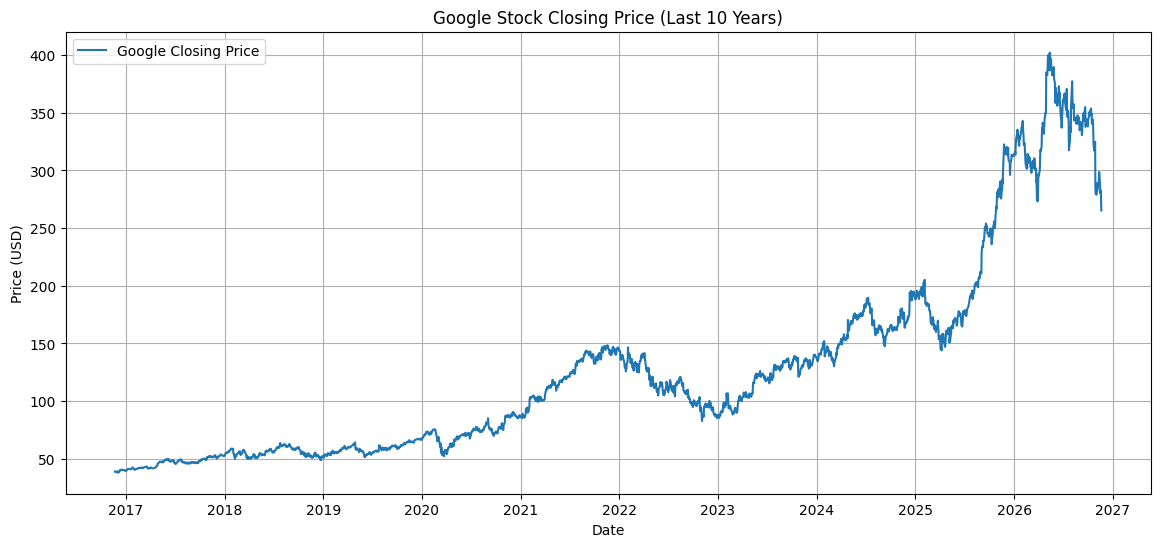

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Closing Price Over Time
plt.figure(figsize=(14, 6))
plt.plot(df.index, df["Close"], label="Google Closing Price")
plt.title("Google Stock Closing Price (Last 10 Years)")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.grid(True)
plt.show()

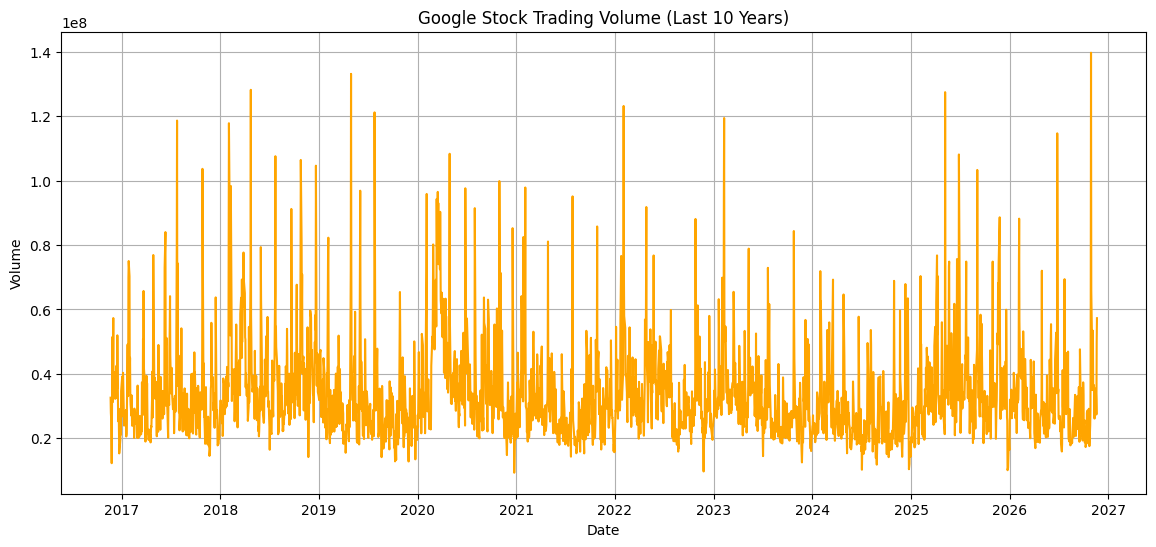

In [10]:
# 2. Trading Volume Over Time
plt.figure(figsize=(14, 6))
plt.plot(df.index, df["Volume"], color="orange")
plt.title("Google Stock Trading Volume (Last 10 Years)")
plt.xlabel("Date")
plt.ylabel("Volume")
plt.grid(True)
plt.show()

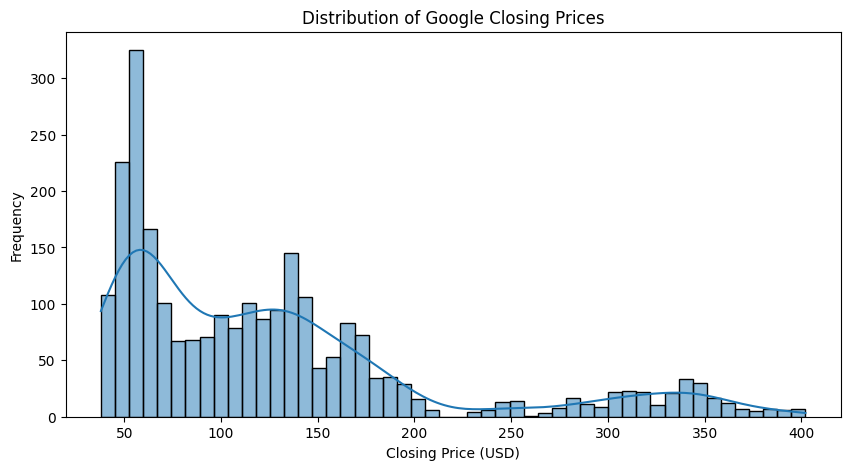

In [11]:
# 3. Distribution of Closing Prices
plt.figure(figsize=(10, 5))
sns.histplot(df["Close"], bins=50, kde=True)
plt.title("Distribution of Google Closing Prices")
plt.xlabel("Closing Price (USD)")
plt.ylabel("Frequency")
plt.show()

# 4. Dataset Preprocessing
## Feature Selection
عندنا 5 أعمدة:
- Open
- High
- Low
- Close
- Volume

we choose close only

لأن هدف المشروع هو التنبؤ بسعر الإغلاق في اليوم التالي اعتمادًا على أسعار الإغلاق السابقة

## Train / Test Split
80% Training Data: لتدريب الموديل.

20% Testing Data: لاختبار الموديل على بيانات لم يتدرب عليها.

## Normalization

الأسعار عندنا بتتراوح تقريبًا من 38 إلى 402 دولار.

هنستخدم MinMaxScaler: عشان يحول القيم لنطاق من 0 إلى 1.

ليه؟

عشان نخلي الأرقام في نطاق موحد، وده بيساعد الموديل أثناء التدريب.

## Sequence Creation
هنخلي الموديل يستخدم آخر 60 يوم تداول عشان يتوقع سعر اليوم التالي.



In [12]:

from sklearn.preprocessing import MinMaxScaler

# 1. Select Closing Price
data = df[['Close']].values

# 2. Split data (80% Training, 20% Testing)
train_size = int(len(data) * 0.8)

# 3. Normalize data
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(data[:train_size])
all_scaled = scaler.transform(data)

# 4. Create sequences
look_back = 60

X_train = []
y_train = []

for i in range(look_back, train_size):
    X_train.append(all_scaled[i-look_back:i, 0])
    y_train.append(all_scaled[i, 0])

X_test = []
y_test = []

for i in range(train_size, len(all_scaled)):
    X_test.append(all_scaled[i-look_back:i, 0])
    y_test.append(all_scaled[i, 0])

# 5. Convert to NumPy arrays
X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

# 6. Reshape data for LSTM
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Display results
print("Training Data Shape:", X_train.shape)
print("Training Labels Shape:", y_train.shape)

print("Testing Data Shape:", X_test.shape)
print("Testing Labels Shape:", y_test.shape)

print("Preprocessing Completed Successfully!")


Training Data Shape: (1951, 60, 1)
Training Labels Shape: (1951,)
Testing Data Shape: (503, 60, 1)
Testing Labels Shape: (503,)
Preprocessing Completed Successfully!


# 5. Model Development / Building

LSTM Layer الأولى: 50 Neurons.



LSTM Layer الثانية: 50 Neurons.



Dropout: لتقليل Overfitting.



Dense Layer: لإنتاج التوقع النهائي.

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build LSTM Model
model = Sequential()

model.add(LSTM(
    units=50,
    return_sequences=True,
    input_shape=(60, 1)
))

model.add(Dropout(0.2))

model.add(LSTM(
    units=50,
    return_sequences=False
))

model.add(Dropout(0.2))

model.add(Dense(25))
model.add(Dense(1))

# Compile Model
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Display Model Architecture
model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train Model
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    shuffle=False
)


Epoch 1/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - loss: 0.0026 - val_loss: 0.0076
Epoch 2/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - loss: 0.0067 - val_loss: 0.0051
Epoch 3/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - loss: 0.0189 - val_loss: 0.0500
Epoch 4/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - loss: 0.0107 - val_loss: 0.0074
Epoch 5/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - loss: 0.0043 - val_loss: 0.0040
Epoch 6/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - loss: 0.0057 - val_loss: 0.0205
Epoch 7/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - loss: 0.0025 - val_loss: 9.4992e-04
Epoch 8/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - loss: 0.0011 - val_loss: 9.1967e-04
Epoch 9/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 10/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 4s 79ms/step - loss: 0.0018 - val_loss: 0.0021
Epoch 11/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 0.0036 - val_loss: 0.0148
Epoch 12/30
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - 

# 6. Model Testing

In [16]:
# Predict stock prices
predictions = model.predict(X_test)

# Convert predictions back to original prices
predicted_prices = scaler.inverse_transform(predictions)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

print("Prediction completed!")
print("Predictions Shape:", predicted_prices.shape)
print("Actual Prices Shape:", actual_prices.shape)


16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
Prediction completed!
Predictions Shape: (503, 1)
Actual Prices Shape: (503, 1)


In [17]:
#Evaluation Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual_prices, predicted_prices)

rmse = np.sqrt(
    mean_squared_error(actual_prices, predicted_prices)
)

mape = np.mean(
    np.abs((actual_prices - predicted_prices) / actual_prices)
) * 100

print("Model Evaluation Results:")
print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")


Model Evaluation Results:
MAE: 26.720366733922635
RMSE: 34.82465936818619
MAPE: 8.600920973156265 %


In [18]:
#Actual vs Predicted
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual_prices, predicted_prices)

rmse = np.sqrt(
    mean_squared_error(actual_prices, predicted_prices)
)

mape = np.mean(
    np.abs((actual_prices - predicted_prices) / actual_prices)
) * 100

print("Model Evaluation Results:")
print("MAE:", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")


Model Evaluation Results:
MAE: 26.720366733922635
RMSE: 34.82465936818619
MAPE: 8.600920973156265 %


# 7. Model Hyperparameter Tuning

In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

configurations = [
    {"units": 32, "dropout": 0.2, "batch": 32},
    {"units": 50, "dropout": 0.2, "batch": 32},
    {"units": 64, "dropout": 0.3, "batch": 64}
]

tuning_results = []
tuned_models = []

for i, config in enumerate(configurations):

    print(f"\nTraining Configuration {i+1}")

    tuned_model = Sequential([
        Input(shape=(60, 1)),
        LSTM(config["units"], return_sequences=True),
        Dropout(config["dropout"]),
        LSTM(config["units"]),
        Dropout(config["dropout"]),
        Dense(25),
        Dense(1)
    ])

    tuned_model.compile(
        optimizer="adam",
        loss="mean_squared_error"
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history_tuned = tuned_model.fit(
        X_train,
        y_train,
        epochs=30,
        batch_size=config["batch"],
        validation_split=0.1,
        callbacks=[early_stop],
        shuffle=False,
        verbose=0
    )

    best_val_loss = min(history_tuned.history["val_loss"])

    tuning_results.append({
        "Configuration": i+1,
        "Units": config["units"],
        "Dropout": config["dropout"],
        "Batch Size": config["batch"],
        "Best Validation Loss": best_val_loss
    })

    tuned_models.append(tuned_model)

# Compare configurations
results_df = pd.DataFrame(tuning_results)

print("\nHyperparameter Tuning Results:")
print(results_df)

# Select best model
best_index = results_df["Best Validation Loss"].idxmin()
best_model = tuned_models[best_index]

print("\nBest Configuration:", best_index + 1)



Training Configuration 1

Training Configuration 2

Training Configuration 3

Hyperparameter Tuning Results:
   Configuration  Units  Dropout  Batch Size  Best Validation Loss
0              1     32      0.2          32              0.001031
1              2     50      0.2          32              0.001059
2              3     64      0.3          64              0.001188

Best Configuration: 1


# Final evaluation

In [20]:
# Predict using the best tuned model
best_predictions = best_model.predict(X_test)

# Convert predictions to original prices
best_predicted_prices = scaler.inverse_transform(
    best_predictions
)

# Evaluate the tuned model
best_mae = mean_absolute_error(
    actual_prices, best_predicted_prices
)

best_rmse = np.sqrt(
    mean_squared_error(actual_prices, best_predicted_prices)
)

best_mape = np.mean(
    np.abs(
        (actual_prices - best_predicted_prices) / actual_prices
    )
) * 100

# Compare original and tuned models
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Original Model": [mae, rmse, mape],
    "Tuned Model": [best_mae, best_rmse, best_mape]
})

print("Final Model Comparison:")
print(comparison)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step
Final Model Comparison:
  Metric  Original Model  Tuned Model
0    MAE       26.720367    25.294345
1   RMSE       34.824659    33.248239
2   MAPE        8.600921     8.157409


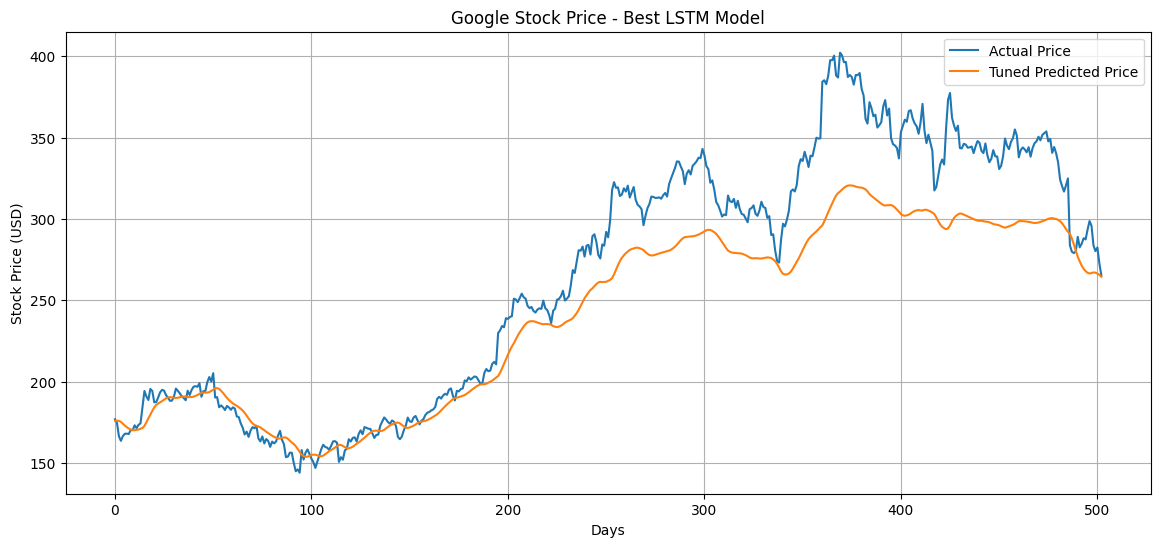

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(actual_prices, label="Actual Price")
plt.plot(best_predicted_prices, label="Tuned Predicted Price")

plt.title("Google Stock Price - Best LSTM Model")
plt.xlabel("Days")
plt.ylabel("Stock Price (USD)")
plt.legend()
plt.grid(True)

plt.show()
